# Полиномы волнового фронта с нуля

Курс в несколько занятий: от «что такое базис» до сверки своей аппроксимации с
отчётом DigitQt и DAPPSIM. Каждое занятие заканчивается **заданием** — его
решаешь сам, в конце есть ячейка-проверка.

| № | Занятие | Главный вопрос |
|---|---|---|
| 1 | Базис | Почему один объект имеет разные «координаты», и все они верны |
| 2 | Метод наименьших квадратов | Как по измеренной карте найти коэффициенты |
| 3 | Ортогональность | Почему у одних базисов коэффициенты «независимы», а у других нет |
| 4 | Переход на круг | ρ, θ; что такое «край» ρ = 1 и почему от него зависят числа |
| 5 | Полиномы Цернике | Построение; нормировки: учебная, Noll, «старший член 1» |
| 6 | Базис Серегина и DigitQt | Пересчёт одного в другое (B2 = 2·Z20 …) |
| 7 | Физический смысл | Наклон, дефокус, астигматизм, кома, сферическая; углы и оси |
| 8 | Практика | Аппроксимация реальной карты и сверка с отчётом |

Справка о том, что делает код DigitQt, — в `notes/uchebnik-interferometriya-i-digitqt.md`, §7.

In [159]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.grid"] = True

---
# Занятие 1. Базис: один объект — разные координаты

## 1.1 Вопрос, с которого всё началось

В отчёте DAPPSIM стоит **B2 = 2**, а DigitQt для той же поверхности пишет
**Z20 = 1**. Расчёт при этом правильный в обоих случаях. Как такое возможно?

Ответ — в слове **базис**. Начнём с того, что знакомо со школы: со стрелок
на плоскости. А потом увидим, что функция — это та же стрелка, только с очень
большим числом координат.

## 1.2 Стрелка на плоскости

Возьмём стрелку (вектор) **v**. Чтобы записать её числами, нужно выбрать
**базис** — набор опорных стрелок, из которых мы её собираем.

* Привычный базис: **e₁** = (1, 0) — «вправо на 1», **e₂** = (0, 1) — «вверх на 1».
  Тогда **v** = 3·**e₁** + 2·**e₂**, и мы говорим «координаты (3, 2)».
* Другой базис: **f₁** = (1, 0), **f₂** = (1, 1) — «по диагонали».
  Та же самая стрелка: **v** = 1·**f₁** + 2·**f₂**. Координаты (1, 2).

Стрелка одна. Числа разные, потому что разные *эталоны*, из которых мы её
складываем. Вопрос «какая у v первая координата — 3 или 1?» не имеет смысла,
пока не сказано, в каком базисе.

в базисе e: (3, 2);  в базисе f: (1, 2)


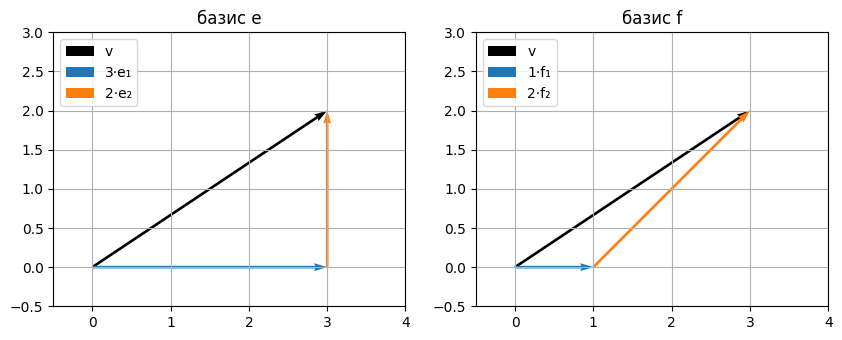

In [160]:
v = np.array([3.0, 2.0])
e1, e2 = np.array([1.0, 0.0]), np.array([0.0, 1.0])
f1, f2 = np.array([1.0, 0.0]), np.array([1.0, 1.0])

# Координаты v в базисе f: решаем a*f1 + b*f2 = v.
a, b = np.linalg.solve(np.column_stack([f1, f2]), v)
print(f"в базисе e: (3, 2);  в базисе f: ({a:g}, {b:g})")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (p, q, cp, cq, name) in zip(
        axes, [(e1, e2, 3, 2, "e"), (f1, f2, a, b, "f")]):
    ax.quiver(0, 0, *v, angles="xy", scale_units="xy", scale=1, color="k", label="v")
    ax.quiver(0, 0, *(cp * p), angles="xy", scale_units="xy", scale=1,
              color="tab:blue", label=f"{cp:g}·{name}₁")
    ax.quiver(*(cp * p), *(cq * q), angles="xy", scale_units="xy", scale=1,
              color="tab:orange", label=f"{cq:g}·{name}₂")
    ax.set_xlim(-0.5, 4); ax.set_ylim(-0.5, 3); ax.set_aspect("equal")
    ax.set_title(f"базис {name}"); ax.legend(loc="upper left")
plt.show()

## 1.3 Функция — тоже стрелка

Профиль поверхности вдоль диаметра — функция **W(x)** на отрезке от −1 до 1.
Измерим её в N точках: получим N чисел. Это и есть «стрелка», только в
N-мерном пространстве (у камеры 1024 точки на строку — значит, 1024 координаты).

Хранить 1024 числа неудобно и непонятно. Удобно сказать: «поверхность — это
столько-то *эталонной параболы* плюс столько-то *эталонного наклона*». Эталонные
функции и есть **базис**, а «столько-то» — **коэффициенты**.

Самый простой базис для гладких профилей — степени x:

$$\{\,1,\; x,\; x^2\,\}$$

Возьмём профиль
$$W(x) = 0{,}3 + 0{,}5\,x + 2\,x^2 .$$
В этом базисе коэффициенты видны сразу: (0,3; 0,5; 2).

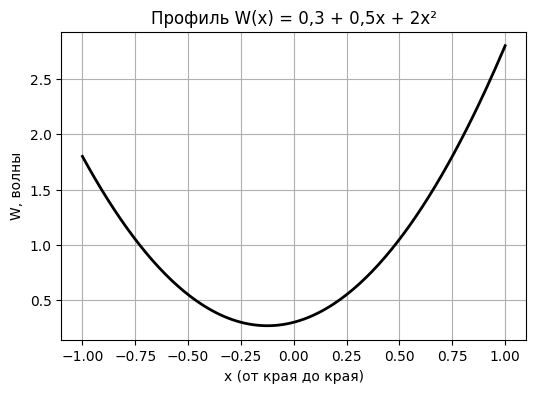

In [161]:
x = np.linspace(-1, 1, 201)          # 201 «пиксель» вдоль диаметра
W = 0.3 + 0.5 * x + 2 * x**2

plt.plot(x, W, "k", lw=2)
plt.xlabel("x (от края до края)"); plt.ylabel("W, волны")
plt.title("Профиль W(x) = 0,3 + 0,5x + 2x²")
plt.show()

## 1.4 Тот же профиль в другом базисе

Теперь другой набор эталонов (это **полиномы Лежандра** — одномерные
«родственники» полиномов Цернике, к ним вернёмся на занятии 3):

$$P_0 = 1,\qquad P_1 = x,\qquad P_2 = \frac{3x^2 - 1}{2}.$$

Обрати внимание: P₂ — тоже парабола, но *другая*: растянута в 1,5 раза и
опущена вниз так, что её среднее по отрезку равно нулю.

Разложим наш W(x) по этому базису. Из формулы для P₂ выражаем x²:

$$x^2 = \frac{2P_2 + 1}{3}$$

и подставляем:

$$W = 0{,}3 + 0{,}5x + 2\cdot\frac{2P_2+1}{3}
    = \underbrace{\left(0{,}3 + \tfrac{2}{3}\right)}_{0{,}967}P_0
    + 0{,}5\,P_1
    + \underbrace{\tfrac{4}{3}}_{1{,}333}P_2 .$$

Коэффициенты теперь (0,967; 0,5; 1,333). Проверим, что кривая та же.

Максимальное расхождение двух записей: 8.881784197001252e-16


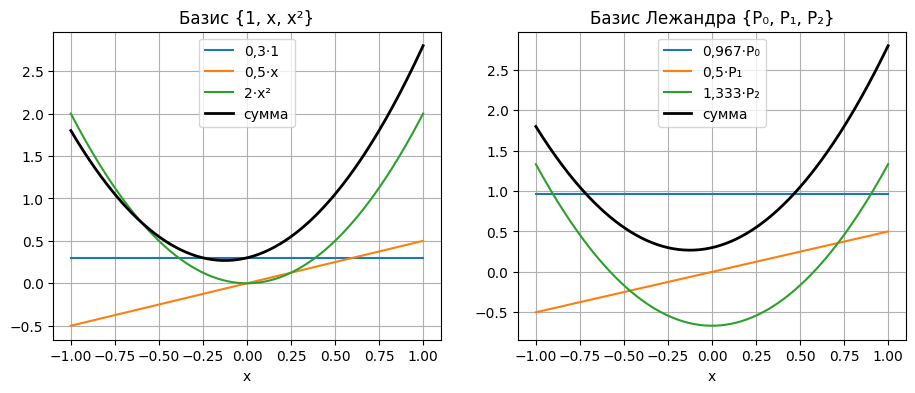

In [162]:
P0 = np.ones_like(x)
P1 = x
P2 = (3 * x**2 - 1) / 2

W_monomials = 0.3 * 1 + 0.5 * x + 2.0 * x**2
W_legendre = (0.3 + 2 / 3) * P0 + 0.5 * P1 + (4 / 3) * P2

print("Максимальное расхождение двух записей:", np.max(np.abs(W_monomials - W_legendre)))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(x, 0.3 * np.ones_like(x), label="0,3·1")
axes[0].plot(x, 0.5 * x, label="0,5·x")
axes[0].plot(x, 2.0 * x**2, label="2·x²")
axes[0].plot(x, W_monomials, "k", lw=2, label="сумма")
axes[0].set_title("Базис {1, x, x²}")
axes[1].plot(x, (0.3 + 2 / 3) * P0, label="0,967·P₀")
axes[1].plot(x, 0.5 * P1, label="0,5·P₁")
axes[1].plot(x, (4 / 3) * P2, label="1,333·P₂")
axes[1].plot(x, W_legendre, "k", lw=2, label="сумма")
axes[1].set_title("Базис Лежандра {P₀, P₁, P₂}")
for ax in axes:
    ax.legend(); ax.set_xlabel("x")
plt.show()

**Чёрные кривые совпадают до машинной точности.** Слагаемые — цветные
кривые — разные, а сумма одна.

Значит, на вопрос «сколько в поверхности параболы?» есть два правильных
ответа — **2** и **1,333** — потому что это ответы на *два разных вопроса*:
«сколько x²» и «сколько (3x²−1)/2».

Заметь ещё одну вещь: изменился и **постоянный член** (0,3 → 0,967).
Эталон P₂ опущен вниз, и чтобы сумма осталась прежней, константа должна
подняться. Эталоны «перекладывают» части поверхности друг другу — к этому
вернёмся на занятии 3, это ключ к пониманию ортогональности.

## 1.5 Где это было в DigitQt

Ровно эта история и случилась с дефокусом. Две программы используют две
*разные параболы* как эталон:

| Кто | Эталон дефокуса | Коэффициент для поверхности 2ρ² − 1 |
|---|---|---|
| DigitQt (учебный Цернике) | Z20 = 2ρ² − 1 | **1** |
| DAPPSIM | ρ² − ½ | **2** |

Эталон DAPPSIM вдвое «ниже», поэтому коэффициент вдвое больше. Поверхность
одна. На занятиях 5–6 разберём все члены и научимся пересчитывать их друг в
друга, не запоминая таблиц.

In [163]:
# Та же проверка, что выше, только для дефокуса на радиусе rho от 0 до 1.
rho = np.linspace(0, 1, 101)
W = 2 * rho**2 - 1                      # поверхность

z20 = 2 * rho**2 - 1                    # эталон DigitQt (учебный Цернике)
b2 = rho**2 - 0.5                       # эталон DAPPSIM

print("W = 1 * Z20 :", np.allclose(W, 1 * z20))
print("W = 2 * B2-эталон:", np.allclose(W, 2 * b2))

W = 1 * Z20 : True
W = 2 * B2-эталон: True


## 1.6 Итог занятия

1. **Базис** — набор эталонных функций; **коэффициенты** — сколько каждого
   эталона взять, чтобы собрать поверхность.
2. Одну и ту же поверхность можно собрать из разных эталонов. Коэффициенты
   будут разные, и все правильные.
3. Число без указания базиса и нормировки эталона ничего не значит. «B2 = 2»
   и «Z20 = 1» — одна и та же поверхность.
4. При смене базиса меняются **не только** коэффициенты при «похожих»
   эталонах, но и остальные (у нас — константа). Почему так бывает и как этого
   избежать — занятие 3.

Пока мы раскладывали «на бумаге», потому что формула W(x) была известна. Но
интерферометр формулу не даёт — он даёт **набор измеренных точек с шумом**.
Как найти коэффициенты по ним — занятие 2, метод наименьших квадратов.

## 1.7 Задание

Профиль
$$W(x) = 1 - x + 3x^2 .$$

1. Найди **на бумаге** его коэффициенты (c₀, c₁, c₂) в базисе Лежандра
   P₀ = 1, P₁ = x, P₂ = (3x² − 1)/2.
2. Впиши их в ячейку ниже и запусти — она проверит.
3. Вопрос на подумать (ответ напиши словами в ячейке ниже): у профиля
   W(x) = x² **среднее значение по отрезку** равно ⅓. Чему равен его
   коэффициент c₀ при P₀ в базисе Лежандра? Совпадение случайно?

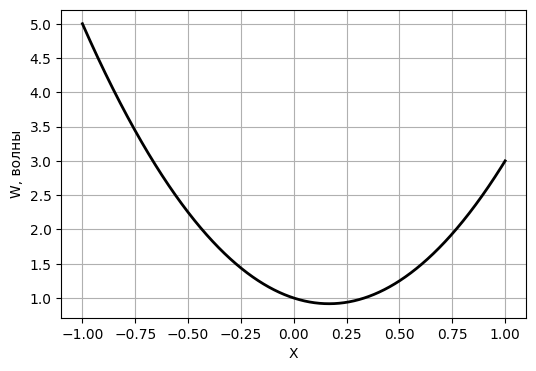

In [164]:
x= np.linspace(-1,1,100001)

np.mean(x)
W = 1 - x + 3 * x**2
plt.plot(x, W, "k", lw=2)
plt.xlabel("X"); plt.ylabel("W, волны")
plt.show()


mean P0 1.0
mean P1 7.275884855334873e-17
mean P2 1.0000000000070233e-05
Максимальное расхождение двух записей: 8.881784197001252e-16


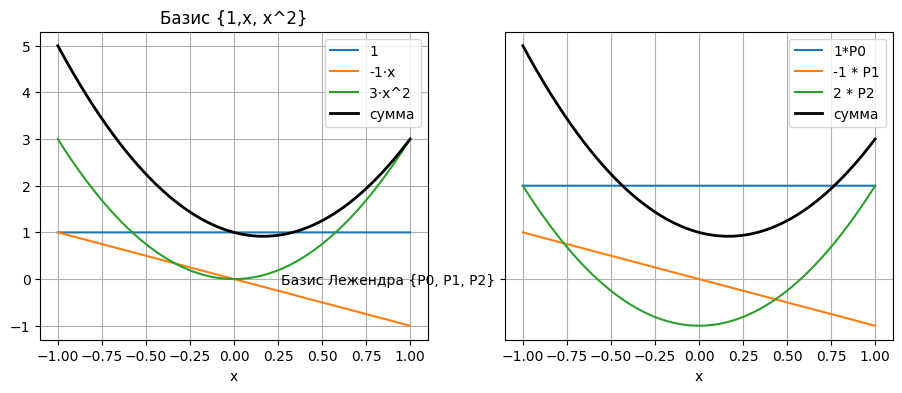

In [165]:
P0 = np.ones_like(x)
P1 = x
P2 = (3 * x**2 - 1)/2
print("mean P0", np.mean(P0))
print("mean P1", np.mean(P1))
print("mean P2", np.mean(P2))
W_monomials = 1 - x + 3 * x**2
W_legendre = 2 * P0 - P1 + 2*P2

print("Максимальное расхождение двух записей:", np.max(np.abs(W_monomials - W_legendre)))


fig, axes = plt.subplots(1, 2, figsize=(11,4))
axes[0].plot(x, 1 * np.ones_like(x), label="1")
axes[0].plot(x, -1 * x, label="-1·x")
axes[0].plot(x, 3 * x**2, label="3·x^2 ")
axes[0].plot(x, W_monomials,"k", lw=2, label="сумма")
axes[0].set_title("Базис {1,x, x^2}")
axes[1].plot(x, 2 * P0, label="1*P0")
axes[1].plot(x, -1 * P1, label="-1 * P1")
axes[1].plot(x, 2* P2, label="2 * P2")
axes[1].plot(x, W_legendre, "k", lw=2, label="сумма")
axes[1].plot("Базис Лежендра {P0, P1, P2}")
for ax in axes:
  ax.legend()
  ax.set_xlabel("x")
plt.show()

In [166]:
# Впиши свои ответы:
c0 = 2
c1 = -1
c2 = 2

def проверить(c0, c1, c2):
    if None in (c0, c1, c2):
        print("Впиши c0, c1, c2.")
        return
    x = np.linspace(-1, 1, 201)
    target = 1 - x + 3 * x**2
    mine = c0 * 1 + c1 * x + c2 * (3 * x**2 - 1) / 2
    err = np.max(np.abs(target - mine))
    if err < 1e-9:
        print("Верно: кривые совпали.")
    else:
        print(f"Пока нет: максимальное расхождение {err:.3f}.")
        plt.plot(x, target, "k", lw=2, label="W(x)")
        plt.plot(x, mine, "--", label="твоя сумма")
        plt.legend(); plt.show()

проверить(c0, c1, c2)

Верно: кривые совпали.


*Ответ на вопрос 3:* …1/3

---
# Занятие 2. Метод наименьших квадратов

## 2.1 В чём проблема

На занятии 1 мы раскладывали **формулу**: W(x) была известна, и коэффициенты
находились алгеброй. Интерферометр формулы не даёт. Он даёт **точки**:
в каждом пикселе — число, и в каждом числе немного шума.

Пусть мы ищем 3 коэффициента (c₀, c₁, c₂), а точек 1000. Получается 1000
уравнений с тремя неизвестными:

$$c_0 + c_1 x_i + c_2 x_i^2 = w_i,\qquad i = 1\ldots1000 .$$

Из-за шума они **противоречат друг другу**: никакая парабола не пройдёт
точно через все 1000 точек. Значит, «решить» систему нельзя — можно только
выбрать коэффициенты, при которых кривая проходит **как можно ближе** к
точкам. Остаётся договориться, что значит «ближе».

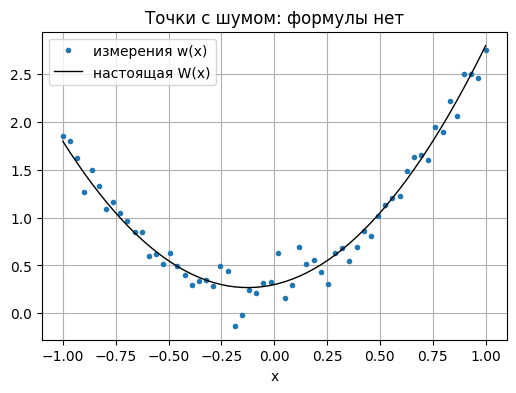

In [167]:
rng = np.random.default_rng(1)
x = np.linspace(-1, 1, 60)                       # 60 «пикселей»
true = 0.3 + 0.5 * x + 2.0 * x**2               # настоящая поверхность (нам неизвестна)
w = true + rng.normal(0, 0.15, x.size)          # то, что «измерил» прибор

plt.plot(x, w, ".", label="измерения w(x)")
plt.plot(x, true, "k", lw=1, label="настоящая W(x)")
plt.legend(); plt.xlabel("x"); plt.title("Точки с шумом: формулы нет")
plt.show()

## 2.2 Идея: минимизировать сумму квадратов невязок

Для любых пробных коэффициентов в каждой точке есть **невязка** —
разница между измерением и кривой:

$$r_i = w_i - (c_0 + c_1 x_i + c_2 x_i^2).$$

Метод наименьших квадратов (МНК) выбирает коэффициенты, при которых

$$S = \sum_i r_i^2 \;\to\; \min .$$

Почему квадраты, а не, скажем, модули:
* квадрат всегда положителен — невязки вверх и вниз не гасят друг друга;
* S — гладкая функция коэффициентов, минимум ищется дифференцированием и
  сводится к **линейной системе** (это главное: решается за один шаг);
* для случайного шума, как у камеры, это ещё и статистически наилучшая оценка.

## 2.3 Самый простой случай: одна константа

Пусть базис — только P₀ = 1, то есть мы приближаем точки горизонтальной
прямой на высоте c. Тогда

$$S(c) = \sum_i (w_i - c)^2,\qquad
\frac{dS}{dc} = -2\sum_i (w_i - c) = 0
\;\Rightarrow\; c = \frac{1}{N}\sum_i w_i .$$

**МНК-константа — это просто среднее.** Узнаёшь? Это ответ на вопрос 3
занятия 1, только с другой стороны: поршень, найденный МНК, — средняя высота.

минимум S при c = 0.980;  среднее измерений = 0.982


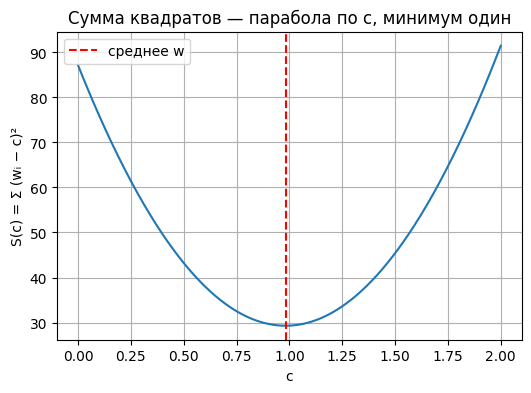

In [168]:
c_grid = np.linspace(0, 2, 401)
S = [np.sum((w - c)**2) for c in c_grid]
best = c_grid[np.argmin(S)]
print(f"минимум S при c = {best:.3f};  среднее измерений = {np.mean(w):.3f}")

plt.plot(c_grid, S)
plt.axvline(np.mean(w), color="r", ls="--", label="среднее w")
plt.xlabel("c"); plt.ylabel("S(c) = Σ (wᵢ − c)²"); plt.legend()
plt.title("Сумма квадратов — парабола по c, минимум один")
plt.show()

## 2.4 Общий случай: матрица

Сложим уравнения всех точек в одну запись. Каждый **столбец** матрицы A —
один эталон базиса, вычисленный во всех точках; каждая **строка** — одна точка:

$$
A = \begin{pmatrix}
1 & x_1 & x_1^2\\
1 & x_2 & x_2^2\\
\vdots & \vdots & \vdots\\
1 & x_N & x_N^2
\end{pmatrix},\qquad
A\,c \approx w .
$$

Приравнивая к нулю производные S по каждому коэффициенту, получаем
**нормальные уравнения** — систему 3×3, сколько бы ни было точек:

$$A^{\mathsf T}A\;c = A^{\mathsf T}w .$$

В numpy это делает `np.linalg.lstsq(A, w)` (он решает то же самое, но
численно аккуратнее, чем прямое обращение AᵀA).

размер A: (60, 3)   размер AᵀA: (3, 3)
нормальные уравнения: [0.2818 0.4813 2.0315]
np.linalg.lstsq:      [0.2818 0.4813 2.0315]
настоящие:            [0.3, 0.5, 2.0]


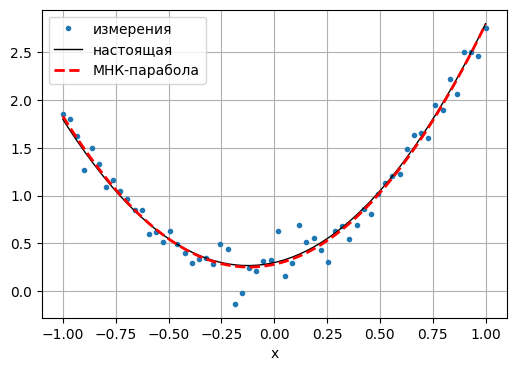

СКО остатка (w − fit): 0.1287   (шум был 0.15)


In [169]:
A = np.column_stack([np.ones_like(x), x, x**2])     # столбцы: 1, x, x²
print("размер A:", A.shape, "  размер AᵀA:", (A.T @ A).shape)

c_normal = np.linalg.solve(A.T @ A, A.T @ w)          # нормальные уравнения
c_lstsq, *_ = np.linalg.lstsq(A, w, rcond=None)       # то же, аккуратнее
print("нормальные уравнения:", np.round(c_normal, 4))
print("np.linalg.lstsq:     ", np.round(c_lstsq, 4))
print("настоящие:           ", [0.3, 0.5, 2.0])

fit = A @ c_lstsq
plt.plot(x, w, ".", label="измерения")
plt.plot(x, true, "k", lw=1, label="настоящая")
plt.plot(x, fit, "r--", lw=2, label="МНК-парабола")
plt.legend(); plt.xlabel("x"); plt.show()

print(f"СКО остатка (w − fit): {np.std(w - fit):.4f}   (шум был 0.15)")

Коэффициенты не совпали с настоящими **точно** — и не должны: шум сдвигает
их случайным образом. Но совпали **близко**, и тем ближе, чем больше точек
(проверим в 2.6). А СКО остатка оказалось ≈ шуму: всё, что не описывается
параболой, — это шум. Это и есть «RMS after» в отчёте S5.

## 2.5 От базиса зависят числа, но не кривая

Подгоним **те же точки** параболой в базисе Лежандра из занятия 1.

In [170]:
A_leg = np.column_stack([np.ones_like(x), x, (3 * x**2 - 1) / 2])
c_leg, *_ = np.linalg.lstsq(A_leg, w, rcond=None)

print("в базисе степеней:  ", np.round(c_lstsq, 4))
print("в базисе Лежандра:  ", np.round(c_leg, 4))
print("кривые совпадают:   ", np.allclose(A @ c_lstsq, A_leg @ c_leg))

# Пересчёт из занятия 1: x² = (2·P₂ + 1)/3  →  c₂(Лежандр) = 2/3·c₂, c₀(Л) = c₀ + c₂/3
c0, c1, c2 = c_lstsq
print("пересчёт формулой:  ", np.round([c0 + c2 / 3, c1, 2 * c2 / 3], 4))

в базисе степеней:   [0.2818 0.4813 2.0315]
в базисе Лежандра:   [0.959  0.4813 1.3543]
кривые совпадают:    True
пересчёт формулой:   [0.959  0.4813 1.3543]


Кривая МНК **одна и та же** в обоих базисах: МНК ищет ближайшую к точкам
кривую среди *всех парабол*, а оба базиса описывают одно и то же множество
парабол. Меняется только запись — по тем же формулам, что на занятии 1.

Отсюда практическое правило: **сравнивать между программами можно кривую
(карту, остаток, RMS) напрямую, а коэффициенты — только после пересчёта в
один базис.** Именно так мы и сравнивали DigitQt с DAPPSIM.

## 2.6 Сколько точек нужно

Повторим «измерение» много раз с новым шумом и посмотрим разброс c₂.

In [171]:
def spread_of_c2(n_points, trials=400, noise=0.15):
    xs = np.linspace(-1, 1, n_points)
    A = np.column_stack([np.ones_like(xs), xs, xs**2])
    values = []
    for _ in range(trials):
        ws = 0.3 + 0.5 * xs + 2.0 * xs**2 + rng.normal(0, noise, xs.size)
        values.append(np.linalg.lstsq(A, ws, rcond=None)[0][2])
    return np.std(values)

for n in [10, 40, 160, 640]:
    print(f"N = {n:4d} точек:  разброс c₂ = {spread_of_c2(n):.4f}")

N =   10 точек:  разброс c₂ = 0.1300
N =   40 точек:  разброс c₂ = 0.0769
N =  160 точек:  разброс c₂ = 0.0388
N =  640 точек:  разброс c₂ = 0.0200


При увеличении числа точек в 4 раза разброс падает примерно в 2 раза:
**ошибка ∝ 1/√N**. На карте 1024×1024 точек ~800 тыс., поэтому коэффициенты
S5 почти не чувствуют шум камеры — их точность ограничивают уже не шум, а
систематика: нормировка радиуса, край апертуры, ошибки развёртки.

## 2.7 Где это в DigitQt

S5 делает ровно то, что мы сделали в 2.4, только:
* точки — все пиксели апертуры (x, y), а не отрезок;
* столбцы матрицы A — эталоны базиса Серегина или Цернике (наклоны,
  дефокус, астигматизм, кома, трефойл, сферическая);
* «Joint least squares» в настройке S5 — это и есть один общий МНК по всем
  выбранным членам сразу.

«RMS before» — СКО карты до вычитания, «RMS after» — СКО остатка w − A·c.

## 2.8 Итог занятия

1. Измерение даёт больше уравнений, чем неизвестных, и они противоречат
   друг другу из-за шума. МНК выбирает коэффициенты с минимальной суммой
   квадратов невязок.
2. Это сводится к нормальным уравнениям AᵀA·c = Aᵀw: столбцы A — эталоны,
   строки — точки. Размер системы — число эталонов, а не число точек.
3. МНК-константа — среднее. Остаток после подгонки — то, что эталоны не
   описывают (шум + «местные ошибки»).
4. Подогнанная кривая не зависит от выбора базиса (если базисы описывают
   одно и то же множество функций) — зависят только числа.
5. Ошибка коэффициентов от шума падает как 1/√N.

## 2.9 Задание

**Часть 1.** Ниже — «измерения» с неизвестной параболой. Построй матрицу A
для базиса {1, x, x²}, найди коэффициенты через `np.linalg.lstsq`, впиши их
и запусти проверку.

**Часть 2 (наблюдение — на ней строится занятие 3).** Добавь в базис ещё
столбец **x³** (данные те же) и подгони снова. Сравни коэффициенты c₀, c₁,
c₂ с частью 1: какие изменились, какие нет? Запиши, что заметил. Объяснять
пока не обязательно — объясним на занятии 3.

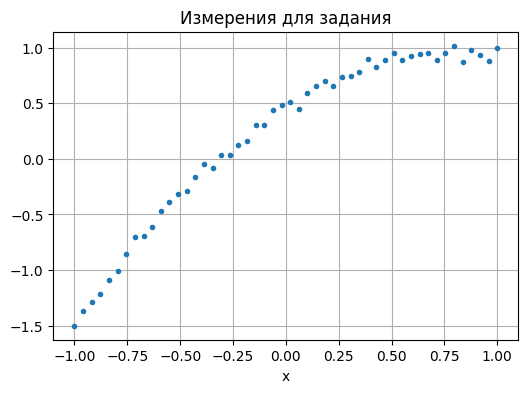

In [172]:
# Данные задания -- не меняй эту ячейку.
rng_task = np.random.default_rng(7)
x_task = np.linspace(-1, 1, 50)
w_task = 0.5 + 1.2 * x_task - 0.8 * x_task**2 + rng_task.normal(0, 0.05, x_task.size)

plt.plot(x_task, w_task, ".")
plt.title("Измерения для задания"); plt.xlabel("x"); plt.show()

In [173]:
# Часть 1: твой код.
A1 = np.column_stack([np.ones_like(x_task), x_task, x_task**2])
c_task, *_ = np.linalg.lstsq(A1, w_task, rcond=None)
     # впиши сюда массив [c0, c1, c2]

def проверить_2(c):
    if c is None:
        print("Впиши c_task.")
        return
    A_ref = np.column_stack([np.ones_like(x_task), x_task, x_task**2])
    ref, *_ = np.linalg.lstsq(A_ref, w_task, rcond=None)
    if np.allclose(np.asarray(c, dtype=float), ref, atol=1e-6):
        print("Верно:", np.round(ref, 4))
    else:
        print("Пока не совпало. Проверь столбцы матрицы: 1, x, x² -- именно в этом порядке.")

проверить_2(c_task)

Верно: [ 0.4688  1.2097 -0.7521]


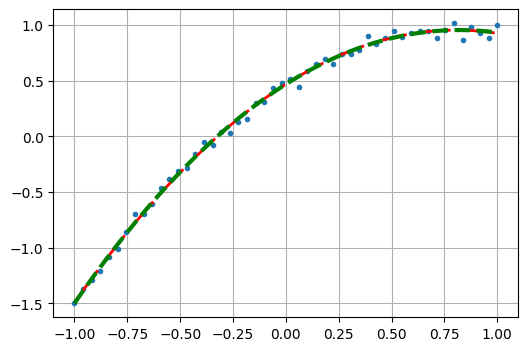

СКО остатка (w − fit1): 0.0413
СКО остатка (w − fit2): 0.0412
[ 0.46876541  1.20966427 -0.75214754]
[ 0.46876541  1.19860629 -0.75214754  0.01771668]


In [174]:
# Часть 2: добавь столбец x**3 и сравни коэффициенты с частью 1.
A2 = np.column_stack([A1, x_task**3])
c, *_ = np.linalg.lstsq(A2, w_task, rcond=None)

fit1 = A1 @ c_task
fit2 = A2 @ c
plt.plot(x_task, w_task, ".", label="измерения")
plt.plot(x_task, fit1, "r--", lw=2, label="3 полинома")
plt.plot(x_task,fit2, "g--", lw=3, label="4 полинома" )
plt.show()
print(f"СКО остатка (w − fit1): {np.std(w_task - fit1):.4f}")
print(f"СКО остатка (w − fit2): {np.std(w_task - fit2):.4f}")
print(c_task)
print(c)


*Что заметил в части 2:* …

---
# Занятие 3. Ортогональность

## 3.1 Наблюдение из задания 2

Ты добавил к базису 1, x, x² ещё x³ и увидел:

| | c₀ | c₁ | c₂ | c₃ |
|---|---|---|---|---|
| 3 полинома | 0,4688 | **1,2097** | −0,7521 | — |
| 4 полинома | 0,4688 | **1,1986** | −0,7521 | 0,0177 |

c₀ и c₂ не сдвинулись ни на одну цифру, а c₁ изменился. Новый эталон x³
«отобрал» часть работы у x, но не тронул 1 и x². Почему именно так?

Ответ — в том, насколько эталоны **похожи** друг на друга. Чтобы это
измерить, нужна одна новая операция.

## 3.2 Скалярное произведение функций

У двух стрелок есть скалярное произведение: **a·b** = a₁b₁ + a₂b₂.
Оно равно нулю, когда стрелки **перпендикулярны** — у них нет общей
составляющей, одна ничего не говорит о другой.

Функция в N точках — та же стрелка из N чисел (занятие 1). Значит, и
скалярное произведение у функций такое же: перемножить по точкам и
сложить. Удобнее брать не сумму, а **среднее** — тогда число не зависит
от количества точек:

$$\langle f, g\rangle = \frac{1}{N}\sum_i f(x_i)\,g(x_i).$$

Если ⟨f, g⟩ = 0, функции называют **ортогональными** (по-гречески —
«прямоугольными»): это перпендикулярность, перенесённая на функции.

Посчитаем ⟨·,·⟩ для всех пар нашего базиса. Такая таблица называется
**матрицей Грама**.

In [175]:
x = np.linspace(-1, 1, 201)
basis = {"1": np.ones_like(x), "x": x, "x²": x**2, "x³": x**3}
names = list(basis)
G = np.array([[np.mean(basis[a] * basis[b]) for b in names] for a in names])

print("      " + "".join(f"{n:>8}" for n in names))
for n, row in zip(names, G):
    print(f"{n:>6}" + "".join(f"{v:8.3f}" for v in row))

             1       x      x²      x³
     1   1.000   0.000   0.337   0.000
     x   0.000   0.337   0.000   0.204
    x²   0.337   0.000   0.204   0.000
    x³   0.000   0.204   0.000   0.147


Смотри на нули. x³ ортогонален **1** и **x²**, но **не** ортогонален x
(⟨x, x³⟩ ≈ 0,2). Ровно те, кого x³ не тронул, и тот, у кого он отобрал
часть работы.

Обрати внимание и на ⟨1, x²⟩ ≈ 0,34 — это твой ответ на вопрос 3 занятия 1:
среднее x² равно 1/3. Значит, 1 и x² тоже **не** ортогональны. Это нам
понадобится в задании.

## 3.3 Почему нули стоят именно там: чётность

Замени x на −x:

* **чётные** функции не меняются: 1, x², x⁴ … (график симметричен);
* **нечётные** меняют знак: x, x³, x⁵ … (график переходит в себя при
  повороте на 180°).

Произведение чётной и нечётной функций — нечётная функция. У нечётной
функции на симметричном отрезке левая половина в точности гасит правую,
поэтому среднее равно нулю. Произведение двух нечётных (x · x³ = x⁴) —
чётная функция, и гасить её нечем.

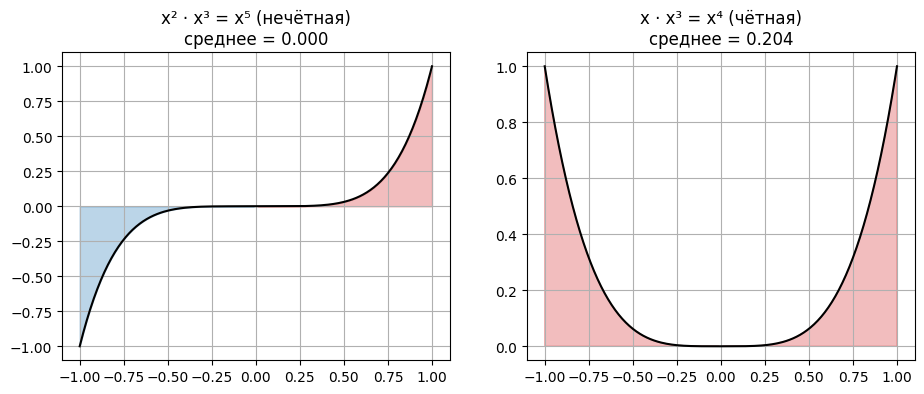

In [176]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
pairs = [(x**2 * x**3, "x² · x³ = x⁵ (нечётная)"), (x * x**3, "x · x³ = x⁴ (чётная)")]
for ax, (f, title) in zip(axes, pairs):
    ax.plot(x, f, "k")
    ax.fill_between(x, f, where=f > 0, color="tab:red", alpha=0.3)
    ax.fill_between(x, f, where=f < 0, color="tab:blue", alpha=0.3)
    ax.set_title(f"{title}\nсреднее = {np.mean(f):.3f}")
plt.show()

## 3.4 Почему ортогональность защищает коэффициенты

Вспомни нормальные уравнения из занятия 2: **AᵀA·c = Aᵀw**. Если разделить
обе части на N, то в матрице AᵀA/N стоят ровно скалярные произведения
эталонов — это та самая матрица Грама из 3.2. А справа — ⟨эталон, w⟩.

* Если все эталоны попарно ортогональны, матрица Грама **диагональная**,
  и система распадается на отдельные уравнения:
  $$c_k = \frac{\langle P_k, w\rangle}{\langle P_k, P_k\rangle}.$$
  Каждый коэффициент — «проекция» измерения на свой эталон, и он не зависит
  от того, какие ещё эталоны есть в базисе. Добавил новый — старые не
  сдвинулись.
* Если два эталона не ортогональны, у них есть общая составляющая. МНК
  должен решить, кому её отдать, и ответ зависит от состава базиса.
  У x и x³ общая составляющая есть — поэтому c₁ сдвинулся.

Проверим на данных задания 2: те же точки, разные базисы.

In [177]:
rng_t = np.random.default_rng(7)          # те же данные, что в задании 2
x_t = np.linspace(-1, 1, 50)
w_t = 0.5 + 1.2 * x_t - 0.8 * x_t**2 + rng_t.normal(0, 0.05, x_t.size)

def fit(columns):
    A = np.column_stack(columns)
    return np.linalg.lstsq(A, w_t, rcond=None)[0]

one, X = np.ones_like(x_t), x_t
print("степени,  3 эталона:", np.round(fit([one, X, X**2]), 4))
print("степени,  4 эталона:", np.round(fit([one, X, X**2, X**3]), 4))

P2 = (3 * X**2 - 1) / 2
P3 = (5 * X**3 - 3 * X) / 2               # полином Лежандра 3-й степени
print("Лежандр,  3 эталона:", np.round(fit([one, X, P2]), 4))
print("Лежандр,  4 эталона:", np.round(fit([one, X, P2, P3]), 4))

степени,  3 эталона: [ 0.4688  1.2097 -0.7521]
степени,  4 эталона: [ 0.4688  1.1986 -0.7521  0.0177]
Лежандр,  3 эталона: [ 0.218   1.2097 -0.5014]
Лежандр,  4 эталона: [ 0.218   1.2092 -0.5014  0.0071]


С Лежандром c₁ сдвинулся в десятки раз меньше — но всё-таки сдвинулся.
Дело в том, что полиномы Лежандра ортогональны на **сплошном** отрезке
(интеграл), а у нас 50 отдельных точек. На сетке «почти ортогональны» —
это не то же самое, что «ортогональны».

## 3.5 Как сделать эталоны ортогональными на своих точках

Рецепт простой: из каждого нового эталона **вычесть его тень** на
предыдущие. Тень f на g — это ⟨f, g⟩/⟨g, g⟩ · g (та же проекция, что
в 3.4). После вычитания общей составляющей не остаётся. Это **процесс
Грама–Шмидта**.

In [178]:
def project_out(f, others):
    # Вычесть из f проекции на уже ортогональные эталоны others.
    for g in others:
        f = f - (np.mean(f * g) / np.mean(g * g)) * g
    return f

Q0 = one
Q1 = project_out(X, [Q0])
Q2 = project_out(X**2, [Q0, Q1])
Q3 = project_out(X**3, [Q0, Q1, Q2])

print("Грам–Шмидт, 3 эталона:", np.round(fit([Q0, Q1, Q2]), 4))
print("Грам–Шмидт, 4 эталона:", np.round(fit([Q0, Q1, Q2, Q3]), 4))
print()
print("Q3 = x³ − a·x,  a =", round(np.mean(X**4) / np.mean(X**2), 4),
      "   (у Лежандра P3 ∝ x³ − 0,6·x)")

Грам–Шмидт, 3 эталона: [ 0.2078  1.2097 -0.7521]
Грам–Шмидт, 4 эталона: [ 0.2078  1.2097 -0.7521  0.0177]

Q3 = x³ − a·x,  a = 0.6242    (у Лежандра P3 ∝ x³ − 0,6·x)


Теперь добавление четвёртого эталона не сдвигает первые три **совсем**.
И посмотри, что получилось из x³: это x³ − 0,62·x, почти Лежандр
(x³ − 0,6·x). Полиномы Лежандра — это и есть результат Грама–Шмидта
над 1, x, x², x³ … на сплошном отрезке. Разница 0,62 против 0,6 — цена
того, что у нас 50 точек, а не бесконечно много.

## 3.6 Где это в DigitQt

* **Два метода S5.** «Совместный МНК» решает нормальные уравнения на
  неортогональном базисе — как наши степени. «Грам–Шмидт по апертуре»
  делает ровно то, что мы сделали в 3.5, только на точках реальной
  апертуры (функция `doCompute` в `ModalAnalysisStage.cpp`).
* **Серегин ↔ Цернике.** У Серегина дефокус — ρ², сферическая — ρ⁴; они
  не ортогональны (как x и x³). Поэтому при совместном МНК часть
  сферической «уходит» в коэффициент дефокуса, и перевести коэффициенты
  Серегина в Цернике одним множителем нельзя. Из-за этого в DigitQt
  смена базиса Серегин ↔ Цернике требует пересчёта S5, а смена нормировки
  Цернике — нет.
* **Полиномы Цернике** построены так, чтобы быть ортогональными на
  **сплошном круге**. На реальной апертуре — с краем, вырезами, отдельными
  пикселями — ортогональность только приближённая (статья SPIE 4771-33
  в `test_data/zernkike`). Про круг — занятие 4.

## 3.7 Итог занятия

1. Скалярное произведение функций ⟨f, g⟩ — среднее произведения по точкам.
   ⟨f, g⟩ = 0 — функции ортогональны, общей составляющей нет.
2. Чётная × нечётная на симметричных точках всегда даёт 0.
3. В ортогональном базисе каждый коэффициент — независимая проекция:
   добавление или удаление эталона не сдвигает остальные.
4. Ортогональность зависит от **набора точек**: на сплошном отрезке,
   на сетке и на реальной апертуре она разная. Грам–Шмидт делает базис
   ортогональным на тех точках, которые есть.

## 3.8 Задание

**Часть 1 (на бумаге).** На сплошном отрезке [−1, 1] найди число a, при
котором x² − a ортогонально 1, то есть среднее (x² − a) равно нулю.
Подсказка: ответ уже встречался на занятии 1. Впиши a в ячейку ниже.
Вопрос на подумать: как x² − a связано с P₂ = (3x² − 1)/2?

In [179]:
a = 1/3   # впиши своё число

def проверить_3(a):
    if a is None:
        print("Впиши a.")
        return
    xs = np.linspace(-1, 1, 200001)
    m = np.mean((xs**2 - a) * 1)
    if abs(m) < 1e-3:
        print(f"Верно: ⟨x² − a, 1⟩ = {m:.5f}")
    else:
        print(f"Пока нет: ⟨x² − a, 1⟩ = {m:.4f}, а должно быть 0.")

проверить_3(a)

Верно: ⟨x² − a, 1⟩ = 0.00000


**Часть 2.** Половина апертуры закрыта: точки есть только при x от 0 до 1.

1. **До запуска** напиши в ячейке ниже предсказание: изменятся ли c₀ и c₂,
   если к 1, x, x² добавить x³? Почему?
2. Потом проверь своим кодом на данных из следующей ячейки (как в
   задании 2, только `x_half`, `w_half`).

In [180]:
# Данные части 2 -- не меняй эту ячейку.
rng_h = np.random.default_rng(11)
x_half = np.linspace(0, 1, 50)
w_half = 0.5 + 1.2 * x_half - 0.8 * x_half**2 + rng_h.normal(0, 0.05, x_half.size)




In [181]:
# Часть 2: твой код -- подгонка 1, x, x² и 1, x, x², x³ на x_half.

A1 = np.column_stack([np.ones_like(x_half), x_half, x_half**2])
c1, *_ = np.linalg.lstsq(A1, w_half, rcond = None)

A2 = np.column_stack([np.ones_like(x_half), x_half, x_half**2, x_half**3])
c2, *_ = np.linalg.lstsq(A2, w_half, rcond = None)

print(c1)
print(c2)


[ 0.51981313  1.09805471 -0.7258225 ]
[ 0.53355084  0.9243726  -0.2872024  -0.2924134 ]


*Ответ на вопрос части 1 (связь с P₂):* …

*Предсказание к части 2 (до запуска):* …

*Что получилось:* …

---
# Занятие 4. Круг и нормировка ρ = 1

## 4.1 От отрезка к кругу

До сих пор всё было одномерным: профиль вдоль диаметра. Но интерферометр
видит **круглый зрачок**, и волновой фронт — функция двух координат.

Для круга удобны **полярные** координаты:

* ρ — расстояние от центра, θ — угол от оси +X против часовой стрелки;
* x = ρ·cos θ, y = ρ·sin θ (Y — вверх, как в DigitQt);
* радиус **нормирован**: ρ = r / R, где R — радиус зрачка. На краю всегда
  ρ = 1, в центре ρ = 0, какого бы размера ни была деталь — 10 мм или 300 мм.

Скалярное произведение — то же самое, что на занятии 3: **среднее
произведения по точкам**, только точки теперь — пиксели внутри круга.
Пиксели камеры стоят равномерной сеткой, поэтому каждый «весит» одинаковую
площадь — для нас это удобно (к этому вернёмся в 4.6).

пикселей внутри круга: 70681


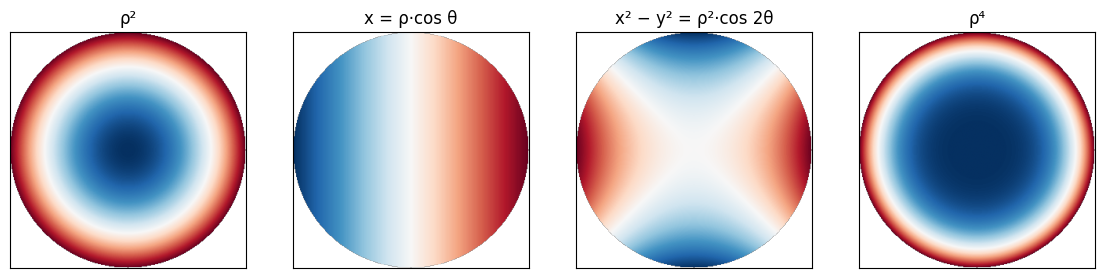

In [182]:
n = 301                                   # пикселей на диаметр
u = np.linspace(-1, 1, n)
X, Y = np.meshgrid(u, -u)                 # -u: строки идут сверху вниз, а Y -- вверх
R = np.hypot(X, Y)
inside = R <= 1

x, y = X[inside], Y[inside]
rho, theta = R[inside], np.arctan2(y, x)
print("пикселей внутри круга:", inside.sum())

def ip(f, g):
    # Скалярное произведение на круге: среднее произведения по пикселям.
    return np.mean(f * g)

def show(values, ax, title):
    # Вернуть значения пикселей круга обратно в квадратную картинку.
    img = np.full(X.shape, np.nan)
    img[inside] = values
    im = ax.imshow(img, extent=(-1, 1, -1, 1), cmap="RdBu_r")
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
    return im

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
show(rho**2, axes[0], "ρ²")
show(x, axes[1], "x = ρ·cos θ")
show(x**2 - y**2, axes[2], "x² − y² = ρ²·cos 2θ")
show(rho**4, axes[3], "ρ⁴")
plt.show()

## 4.2 Среднее на круге — не то же, что на отрезке

На занятии 1 ты нашёл: среднее x² на отрезке равно **1/3**. Чему равно
среднее ρ² по кругу? Хочется сказать «тоже 1/3», но посчитаем.

среднее x² на отрезке: 0.3333
среднее ρ² по кругу:   0.5


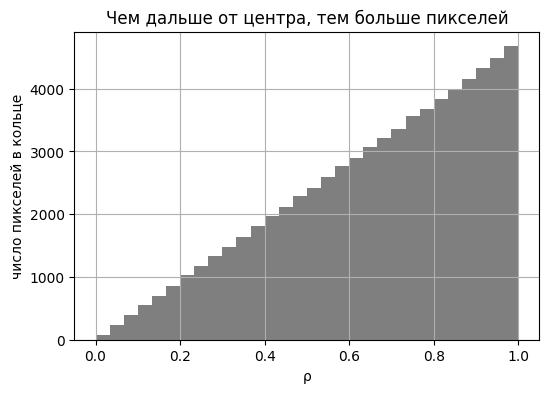

In [183]:
print("среднее x² на отрезке:", round(np.mean(np.linspace(-1, 1, 100001)**2), 4))
print("среднее ρ² по кругу:  ", round(ip(rho**2, 1), 4))

# Почему так: сколько пикселей приходится на каждое кольцо ρ.
plt.hist(rho, bins=30, color="tab:gray")
plt.xlabel("ρ"); plt.ylabel("число пикселей в кольце")
plt.title("Чем дальше от центра, тем больше пикселей")
plt.show()

Среднее ρ² по кругу — около **1/2**, а не 1/3. Причина на гистограмме:
кольцо радиуса ρ длиннее, чем кольцо у центра (длина окружности 2πρ),
поэтому пикселей у края больше, и край сильнее тянет среднее вверх.
На отрезке все точки равноправны, а у круга «весит» каждое кольцо
пропорционально ρ.

Отсюда первое следствие. На отрезке x² − 1/3 ортогонально 1 (задание 3).
На круге ортогонально 1 будет **ρ² − 1/2**. Узнаёшь? Это эталон дефокуса
в отчёте DAPPSIM (занятие 1), а 2ρ² − 1 = 2·(ρ² − 1/2) — дефокус Цернике.

## 4.3 Угол: своя «чётность»

На отрезке нули давала чётность. На круге есть ещё одна симметрия —
**поворот**. Функции cos θ, sin θ, cos 2θ, sin 2θ … за полный оборот
гасят друг друга так же, как чётная и нечётная на отрезке. Поэтому члены
с **разным угловым числом** (наклон — 1, астигматизм — 2, трилистник — 3)
ортогональны друг другу автоматически, а cos и sin одного числа —
тоже (X- и Y-составляющие).

Проверим матрицей Грама для привычных членов.

In [184]:
terms = {
    "1": np.ones_like(rho),
    "x": x, "y": y,                        # наклон
    "ρ²": rho**2,                          # дефокус (пока без вычитания)
    "x²−y²": x**2 - y**2, "2xy": 2 * x * y,  # астигматизм
    "ρ⁴": rho**4,                          # сферическая (пока без вычитания)
}
names = list(terms)
G = np.array([[ip(terms[a], terms[b]) for b in names] for a in names])
print("       " + "".join(f"{n:>7}" for n in names))
for n, row in zip(names, G):
    print(f"{n:>7}" + "".join(f"{v:7.3f}" for v in row))

             1      x      y     ρ²  x²−y²    2xy     ρ⁴
      1  1.000  0.000 -0.000  0.500 -0.000 -0.000  0.333
      x  0.000  0.250 -0.000  0.000  0.000 -0.000  0.000
      y -0.000 -0.000  0.250 -0.000  0.000  0.000 -0.000
     ρ²  0.500  0.000 -0.000  0.333 -0.000 -0.000  0.250
  x²−y² -0.000  0.000  0.000 -0.000  0.166  0.000  0.000
    2xy -0.000 -0.000  0.000 -0.000  0.000  0.167  0.000
     ρ⁴  0.333  0.000 -0.000  0.250  0.000  0.000  0.200


Почти вся таблица — нули. Ненулевыми остались только связи внутри
**радиального семейства** 1, ρ², ρ⁴ (у них угловое число одно — 0, гасить
нечем) и диагональ. Это та же картина, что на отрезке с 1, x², x⁴.

(На диагонали у x²−y² и 2xy одно число, а у x и y — другое: «размер»
эталонов разный. Это вопрос нормировки, о ней в 4.5.)

## 4.4 Грам–Шмидт на круге: откуда берутся радиальные полиномы Цернике

Сделаем радиальное семейство ортогональным тем же рецептом, что в 3.5:
из каждого нового эталона вычитаем тени на предыдущие.

In [185]:
def project_out(f, others):
    for g in others:
        f = f - (ip(f, g) / ip(g, g)) * g
    return f

one = np.ones_like(rho)
Q1 = project_out(rho**2, [one])
Q2 = project_out(rho**4, [one, Q1])

# Прочитаем, что получилось, в степенях ρ: разложим Q по 1, ρ², ρ⁴.
monomials = np.column_stack([one, rho**2, rho**4])
for name, Q in [("Q1", Q1), ("Q2", Q2)]:
    c = np.linalg.lstsq(monomials, Q, rcond=None)[0]
    print(f"{name} = {c[2]:+.3f}·ρ⁴ {c[1]:+.3f}·ρ² {c[0]:+.3f}")

Q1 = +0.000·ρ⁴ +1.000·ρ² -0.500
Q2 = +1.000·ρ⁴ -1.000·ρ² +0.167


Получилось (с точностью до того, что пикселей конечное число):

* **Q1 = ρ² − 1/2**,
* **Q2 = ρ⁴ − ρ² + 1/6**.

Это радиальные части Цернике для дефокуса и сферической — **в нормировке
«старший коэффициент равен 1»** (ISO 14999, ОСТ 3-5476-83, B2 и B4 в
отчёте DAPPSIM). Полиномы Цернике — это и есть Грам–Шмидт на круге, как
Лежандр — Грам–Шмидт на отрезке.

## 4.5 Нормировка: какой «длины» эталон

Грам–Шмидт задаёт **форму** эталона, но не его **масштаб**: Q1 и 2·Q1
одинаково ортогональны всему остальному. Масштаб выбирают договорённостью.
Это и есть три нормировки, которые теперь есть в списке на S5 DigitQt:

| Нормировка | Правило | Дефокус | Сферическая |
|---|---|---|---|
| ISO / ОСТ / DAPPSIM | старший коэффициент = 1 | ρ² − 1/2 | ρ⁴ − ρ² + 1/6 |
| единичная (Борн–Вольф) | значение на краю (ρ = 1) = 1 | 2ρ² − 1 | 6ρ⁴ − 6ρ² + 1 |
| RMS (ANSI, Zemax) | СКО эталона по кругу = 1 | √3·(2ρ² − 1) | √5·(6ρ⁴ − 6ρ² + 1) |

Множители можно не запоминать — их можно посчитать.

In [186]:
for name, Q in [("дефокус", Q1), ("сферическая", Q2)]:
    edge = Q[np.argmax(rho)]                 # значение на краю, ρ ≈ 1
    unit = Q / edge                          # единичная нормировка
    rms = unit / np.sqrt(ip(unit, unit))     # RMS-нормировка
    print(f"{name:12s}: от ISO к единичной ×{1 / edge:.2f},"
          f"  от единичной к RMS ×{1 / np.sqrt(ip(unit, unit)):.3f}")
print("для сравнения: √3 =", round(np.sqrt(3), 3), "  √5 =", round(np.sqrt(5), 3))

дефокус     : от ISO к единичной ×2.00,  от единичной к RMS ×1.732
сферическая : от ISO к единичной ×6.00,  от единичной к RMS ×2.237
для сравнения: √3 = 1.732   √5 = 2.236


Те же 2 и 6, те же √3 и √5, что стоят в `ZernikeNormalization.h`. Одна
и та же поверхность в трёх нормировках — три разных числа, и все верные
(занятие 1, только теперь на круге).

## 4.6 Когда круг не круг

Ортогональность Цернике держится на двух вещах: точки покрывают **весь**
круг и край точно на **ρ = 1**. Оба условия на практике нарушаются.

* **Вырез или затенение.** У телескопа Кассегрена в центре дыра, у детали
  на стенде может быть закрыт край оправой. Это как половина отрезка
  в задании 3: симметрия пропадает, нули в матрице Грама — тоже.
* **Неравные веса точек.** Если точки стоят не равномерной сеткой (сетка
  МКЭ, полярная выборка), каждую нужно взвешивать её площадью — иначе
  ортогональности нет даже на целом круге (статья SPIE 4771-33, табл. 4).
  У камеры пиксели равные, поэтому простое среднее нам подходит.

Посмотрим на кольцо с дырой в центре радиусом 0,3.

In [187]:
Z20 = 2 * rho**2 - 1
Z40 = 6 * rho**4 - 6 * rho**2 + 1
ring = rho >= 0.3

print("                  полный круг   кольцо 0,3…1")
for label, f, g in [("⟨1, Z20⟩", one, Z20), ("⟨1, Z40⟩", one, Z40), ("⟨Z20, Z40⟩", Z20, Z40),
                    ("⟨x, y⟩", x, y)]:
    print(f"{label:12s} {ip(f, g):12.4f} {np.mean(f[ring] * g[ring]):14.4f}")

                  полный круг   кольцо 0,3…1
⟨1, Z20⟩          -0.0001         0.0898
⟨1, Z40⟩          -0.0001        -0.0738
⟨Z20, Z40⟩        -0.0001         0.0678
⟨x, y⟩            -0.0000        -0.0000


На кольце радиальные члены перестали быть ортогональными (пистон «цепляет»
дефокус, дефокус — сферическую), а x и y остались: дыра в центре круглая,
поворотная симметрия не нарушилась. Сломать угловую ортогональность может
только **несимметричная** потеря — например, закрытый с одной стороны край.

## 4.7 Где это в DigitQt

* **Нормировка ρ = 1.** S5 переводит пиксели в зрачковые координаты x, y,
  где край апертуры — радиус 1 (`ApertureSamples.h`). Центр и радиус берутся
  по прямоугольнику непустых пикселей карты (`computeApertureGeometry`).
* **Эрозия края.** Самый крайний ободок карты ненадёжен, поэтому
  `collectApertureSamples` выбрасывает ещё `edgeErosionPixels` пикселей
  (по умолчанию 2). Радиус при этом **не** уменьшается: данные кончаются
  чуть раньше ρ = 1. Как это влияет на коэффициенты — твоё задание.
* **«Грам–Шмидт по апертуре»** делает то, что мы сделали в 4.4, но на точках
  реальной апертуры с вырезами и эрозией — тогда коэффициенты снова не
  зависят от набора членов, хотя полиномы уже не учебные Цернике.

## 4.8 Итог занятия

1. На круге каждое кольцо «весит» пропорционально ρ, поэтому среднее ρ²
   равно 1/2, а не 1/3.
2. Члены с разным угловым числом ортогональны из-за поворотной симметрии.
   Неортогональны только члены одного углового числа с разной степенью ρ.
3. Грам–Шмидт над 1, ρ², ρ⁴ на круге даёт радиальные полиномы Цернике.
   Форму задаёт ортогональность, масштаб — договорённость (нормировка).
4. Ортогональность требует целого круга, края на ρ = 1 и равных весов точек.
   Вырезы и неверный радиус её ломают.

## 4.9 Задание

**Часть 1 (на бумаге).** Найди среднее ρ² по кругу единичного радиуса
точно, а не по пикселям. Подсказка: кольцо радиуса ρ толщиной dρ имеет
площадь 2πρ·dρ, а весь круг — π. Среднее — это интеграл ρ² по площади,
делённый на площадь. Впиши ответ в ячейку ниже.

In [191]:
mean_rho2 = 0.5   # впиши своё число

def проверить_4(value):
    if value is None:
        print("Впиши mean_rho2.")
        return
    if abs(value - 0.5) < 1e-6:
        print("Верно: 1/2.")
    else:
        print(f"Пока нет: {value}. По пикселям выходит {ip(rho**2, 1):.4f}.")

проверить_4(mean_rho2)

Верно: 1/2.


**Часть 2. Радиус чуть больше, чем данные.** Поверхность — чистая
сферическая: W = 0,3·(6ρ⁴ − 6ρ² + 1) на круге радиуса 1. Но программа
нормировала радиус неточно: считает, что зрачок радиуса **1,05** (так
бывает, когда край обрезан эрозией, а радиус взят по старому контуру).
То есть в формулы подставляется ρ' = ρ / 1,05.

1. **До запуска** напиши предсказание:
   * изменится ли остаток (СКО после вычитания)?
   * какие коэффициенты появятся, кроме сферической, и изменится ли сама
     сферическая?
2. Потом проверь: подгони W эталонами 1, Z20(ρ'), Z40(ρ') и сравни с
   подгонкой при правильном ρ. Данные — в следующей ячейке.

In [189]:
# Данные части 2 -- не меняй эту ячейку.
W_task = 0.3 * (6 * rho**4 - 6 * rho**2 + 1)
rho_wrong = rho / 1.05

In [190]:
# Часть 2: твой код -- две подгонки (ρ и rho_wrong), коэффициенты и СКО остатка.

*Предсказание к части 2 (до запуска):* …

*Что получилось и почему:* …